# Beach Carrying Capacity â€” Analysis Notebook

Computes the headline metrics of `PAPER.md`. **All inputs live in this repo** (`../data/`):

| file | contents |
|---|---|
| `data/people_zones.csv` | per-frame people counts by zone + `ts_suspect` flag |
| `data/mask_stats_clean.csv` | per-frame seg class stats (deduplicated) |
| `data/waterline_stats.csv` | per-frame waterline y-position |
| `data/detections.csv` | all 284k person boxes |
| `data/frame_weather.csv` | per-image weather join (HCDP), regenerated below |
| `data/external/hcdp_5min_lahaina.csv` | HCDP Lahaina WTP 5-min obs |
| `data/external/CO-OPS__1615680__hr.csv` | NOAA Kahului hourly water level |
| `data/night.txt`, `night_detections.txt` | night-gated frames (identical for both models) |

Note on `ts_suspect`: ~100 analyzed frames carry capture-clock anomalies â€” bright
daytime images stamped at computed local night hours. They are flagged in
`people_zones.csv` and excluded from hour-of-day analyses below.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
%matplotlib inline

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

REPO = Path.cwd().parent if Path.cwd().name == 'analysis' else Path('..')
DATA = REPO / 'data'
EXT  = DATA / 'external'
PEOPLE_CSV    = DATA / 'people_zones.csv'
MASKSTATS_CSV = DATA / 'mask_stats_clean.csv'
WATERLINE_CSV = DATA / 'waterline_stats.csv'
DETECTIONS_CSV = DATA / 'detections.csv'
HCDP_CSV  = EXT / 'hcdp_5min_lahaina.csv'
TIDE_CSV  = EXT / 'CO-OPS__1615680__hr.csv'

OUT = Path('out'); OUT.mkdir(exist_ok=True)

# Effective ground scale anchored to 3 hand-measured Google Maps polygons
# (1,779 / 2,820 / 3,387 m^2 at high/mid/low water), matched to px_beach
# p10/p50/p90 -> pooled k = 0.0138 m^2/px (anchors agree within ~7%).
# Still an approximation (no per-pixel homography) â€” see PAPER.md 4.4/6.
M2_PER_PX = 0.0138
CAMERA_MOVE = pd.Timestamp('2026-01-27 22:29:35')  # UTC
DAY_START_H, DAY_END_H = 5.0, 20.0   # same day window as --time day

## 1. Load and fuse the per-frame products


In [2]:
pz = pd.read_csv(PEOPLE_CSV)
ms = pd.read_csv(MASKSTATS_CSV)

pz['utc'] = pd.to_datetime(pz['utc_ts'], utc=True).dt.tz_localize(None)
pz['local'] = pd.to_datetime(pz['local_dt'])
ms['utc'] = pd.to_datetime(ms['utc_ts'], utc=True).dt.tz_localize(None)
ms['local'] = pd.to_datetime(ms['local_dt'])

day = ms[ms['is_night'] == 0].merge(
    pz[['image', 'ts_suspect', 'people_beach', 'people_water', 'people_other',
        'people_total', 'n_detections']],
    on='image', how='left').fillna({'ts_suspect': 0, 'people_beach': 0,
        'people_water': 0, 'people_other': 0, 'people_total': 0,
        'n_detections': 0})
day = day.sort_values('local').reset_index(drop=True)

print(f'frames on disk   : {len(ms):,}')
print(f'  night (sat<5)  : {(ms.is_night==1).sum():,}')
print(f'  day analyzed   : {len(day):,}   of which ts_suspect: {int(day.ts_suspect.sum())}')
print(f'  local window   : {day.local.min()}  ->  {day.local.max()}')
print(f'person detections: {int(day.people_total.sum()):,}')
print(f'  beach/water/other: {int(day.people_beach.sum()):,} / {int(day.people_water.sum()):,} / {int(day.people_other.sum()):,}')
day.head(3)

frames on disk   : 21,639
  night (sat<5)  : 9,604
  day analyzed   : 12,035   of which ts_suspect: 108
  local window   : 2026-01-05 10:56:54  ->  2026-10-19 18:34:06
person detections: 284,325
  beach/water/other: 167,069 / 99,084 / 18,172


,image,utc_ts,local_dt,local_hour,mean_sat,median_gray,is_night,roi_masked,roi_px,px_background,...,pct_lowconf_fill,pct_voronoi_fill,utc,local,ts_suspect,people_beach,people_water,people_other,people_total,n_detections
0,youtube_snapshot_Kaanapali_20260105_205654.jpg,2026-01-05T20:56:54,2026-01-05T10:56:54,10.933,67.68,165.0,0,1,646924.0,2727.0,...,0.0,0.0,2026-01-05 20:56:54,2026-01-05 10:56:54,0,24,10,2,36,36
1,youtube_snapshot_Kaanapali_20260105_211158.jpg,2026-01-05T21:11:58,2026-01-05T11:11:58,11.183,68.55,157.0,0,1,646876.0,3390.0,...,0.0,0.0,2026-01-05 21:11:58,2026-01-05 11:11:58,0,27,12,4,43,43
2,youtube_snapshot_Kaanapali_20260105_212702.jpg,2026-01-05T21:27:02,2026-01-05T11:27:02,11.450,65.61,157.0,0,1,646239.0,3072.0,...,0.0,0.0,2026-01-05 21:27:02,2026-01-05 11:27:02,0,30,16,3,49,49


## 2. Occupancy time series

Daily mean people per frame by zone. Camera-move cutoff (Jan 27) marked.

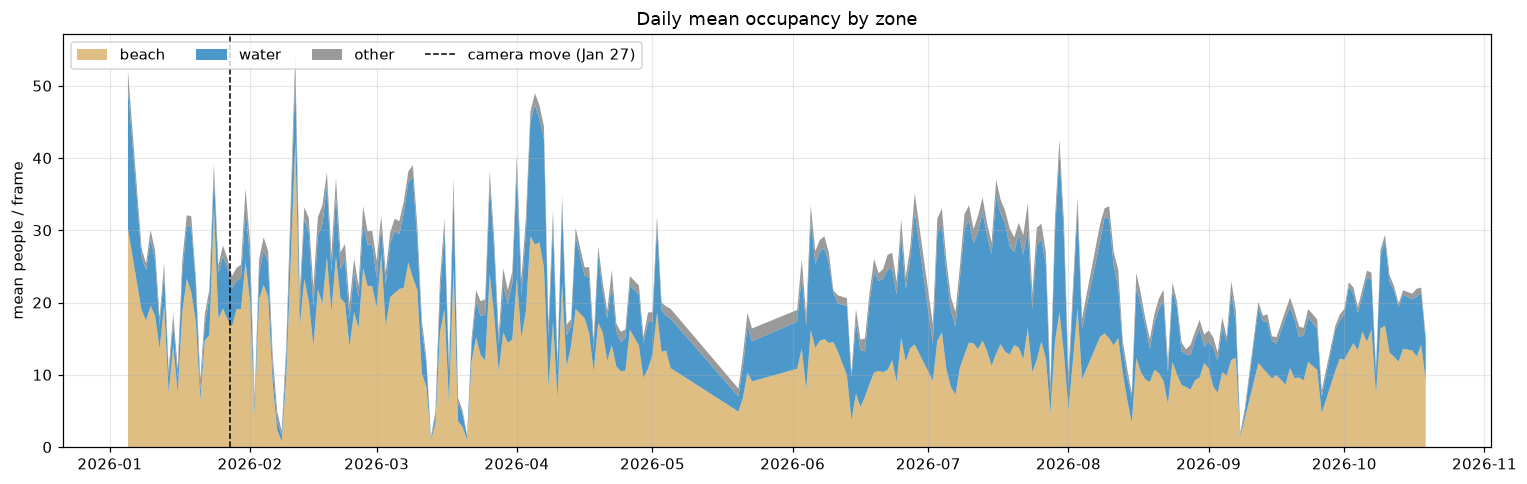

busiest day : 2026-02-11 54.4/frame
quietest day: 2026-03-13 1.36/frame


In [3]:
MIN_F = 10
daily = (day.set_index('local')
           .resample('1D')
           .agg(beach=('people_beach','mean'), water=('people_water','mean'),
                other=('people_other','mean'), total=('people_total','mean'),
                pct_beach=('pct_beach','mean'), n=('people_total','size')))
daily = daily[daily.n >= MIN_F]

fig, ax = plt.subplots(figsize=(14,4.5))
ax.stackplot(daily.index, daily['beach'], daily['water'], daily['other'],
             labels=['beach','water','other'],
             colors=['#d9b36c','#2e86c1','#888888'], alpha=0.85)
ax.axvline(CAMERA_MOVE - pd.Timedelta(hours=10), color='k', ls='--', lw=1,
           label='camera move (Jan 27)')
ax.set_ylabel('mean people / frame'); ax.set_title('Daily mean occupancy by zone')
ax.legend(loc='upper left', ncol=4)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.tight_layout(); plt.savefig(OUT/'daily_occupancy.png'); plt.show()
print('busiest day :', daily.total.idxmax().date(), f'{daily.total.max():.1f}/frame')
print('quietest day:', daily.total.idxmin().date(), f'{daily.total.min():.2f}/frame')

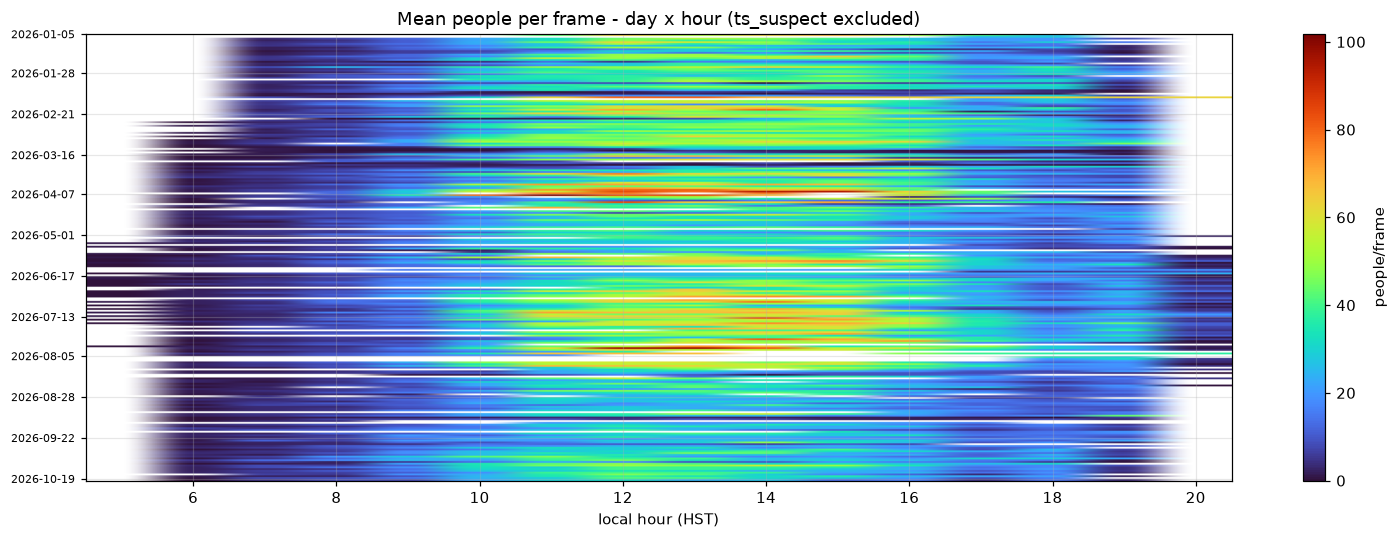

In [4]:
# day x hour heatmap - ts_suspect frames excluded (bad timestamps)
pv = day[day.ts_suspect == 0].copy()
pv['hr'] = pv['local_hour'].round().astype(int)
pv['date'] = pv['local'].dt.date
pivot = pv.pivot_table(index='date', columns='hr', values='people_total',
                       aggfunc='mean')
fig, ax = plt.subplots(figsize=(14,5))
im = ax.imshow(pivot.values, aspect='auto', cmap='turbo',
               extent=[pivot.columns.min()-0.5, pivot.columns.max()+0.5,
                       len(pivot), 0])
yt = np.linspace(0, len(pivot)-1, min(12, len(pivot))).astype(int)
ax.set_yticks(yt); ax.set_yticklabels([str(d) for d in pivot.index[yt]], fontsize=7)
ax.set_xlabel('local hour (HST)')
ax.set_title('Mean people per frame - day x hour (ts_suspect excluded)')
fig.colorbar(im, ax=ax, label='people/frame')
plt.tight_layout(); plt.savefig(OUT/'occupancy_heatmap.png'); plt.show()

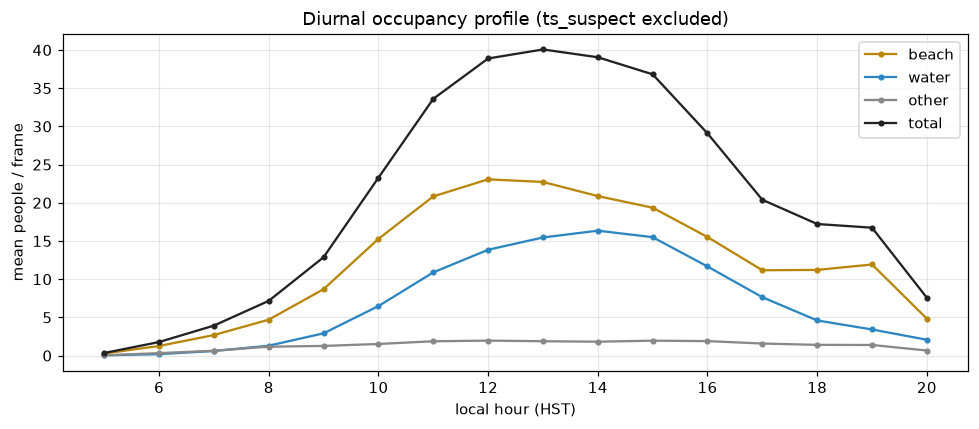

peak total hour: 13 (40.1 people/frame)


In [5]:
# diurnal profile - ts_suspect excluded; no one on the beach at night
dd = day[day.ts_suspect == 0].copy()
dd['hr'] = dd['local_hour'].round().astype(int)
prof = dd.groupby('hr')[['people_beach','people_water','people_other',
                         'people_total']].mean()
fig, ax = plt.subplots(figsize=(9,4))
for c, col, lab in [('people_beach','#b8860b','beach'),
                    ('people_water','#2e86c1','water'),
                    ('people_other','#888888','other'),
                    ('people_total','#222222','total')]:
    ax.plot(prof.index, prof[c], '-o', ms=3, color=col, label=lab)
ax.set_xlabel('local hour (HST)'); ax.set_ylabel('mean people / frame')
ax.set_title('Diurnal occupancy profile (ts_suspect excluded)'); ax.legend()
plt.tight_layout(); plt.savefig(OUT/'diurnal_profile.png'); plt.show()
print('peak total hour:', prof.people_total.idxmax(),
      f'({prof.people_total.max():.1f} people/frame)')

## 3. Beach area per capita


using PROVISIONAL scale (no calibration yet)
mean visible beach area : 2,673 m^2
mean beach people/frame : 13.9
median m^2/person       : 200
p10 (crowded)           : 85
p90 (empty)             : 1,025


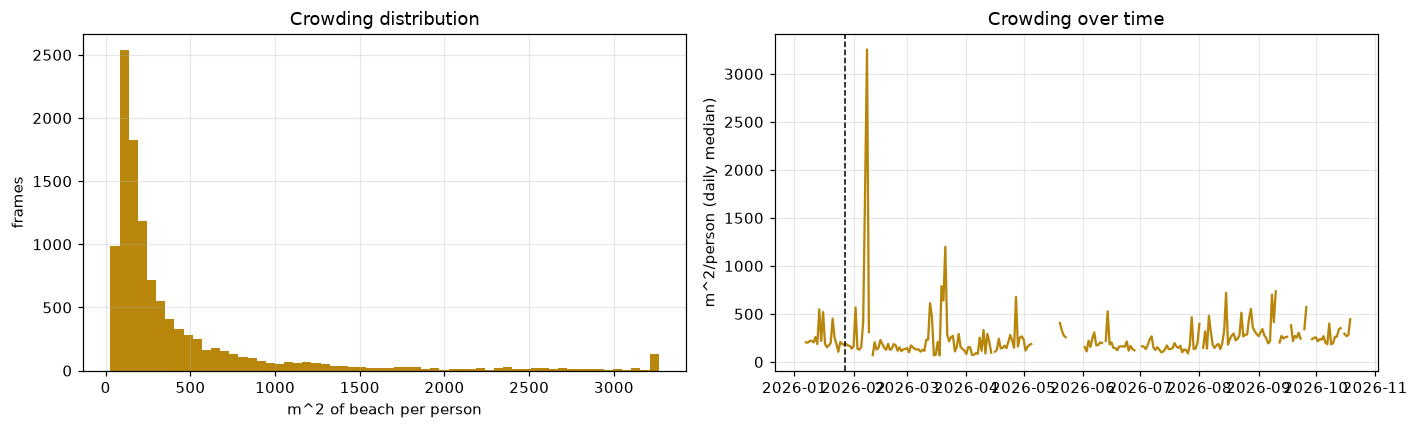

In [6]:
# Prefer calibrated per-pixel areas (calibrate_homography.py) when available;
# fall back to the provisional uniform scale otherwise.
AREA_CSV = DATA / 'frame_area_m2.csv'
if AREA_CSV.exists():
    day = day.merge(pd.read_csv(AREA_CSV)[['image','beach_m2']], on='image', how='left')
    occ = day[(day['people_beach'] > 0) & day['beach_m2'].notna()].copy()
    print('using CALIBRATED beach areas (homography)')
else:
    occ = day[day['people_beach'] > 0].copy()
    occ['beach_m2'] = occ['px_beach'] * M2_PER_PX
    print('using PROVISIONAL scale (no calibration yet)')

occ['m2_per_person'] = occ['beach_m2'] / occ['people_beach']
occ['px2_per_person'] = occ['px_beach'] / occ['people_beach']

print(f'mean visible beach area : {occ.beach_m2.mean():,.0f} m^2')
print(f'mean beach people/frame : {day.people_beach.mean():.1f}')
print(f'median m^2/person       : {occ.m2_per_person.median():,.0f}')
print(f'p10 (crowded)           : {occ.m2_per_person.quantile(0.10):,.0f}')
print(f'p90 (empty)             : {occ.m2_per_person.quantile(0.90):,.0f}')

fig, axs = plt.subplots(1, 2, figsize=(13,4))
axs[0].hist(occ['m2_per_person'].clip(0, occ.m2_per_person.quantile(.99)),
            bins=60, color='#b8860b')
axs[0].set_xlabel('m^2 of beach per person')
axs[0].set_ylabel('frames'); axs[0].set_title('Crowding distribution')
roll = occ.set_index('local')['m2_per_person'].resample('1D').median()
axs[1].plot(roll.index, roll.values, color='#b8860b', lw=1.5)
axs[1].axvline(CAMERA_MOVE - pd.Timedelta(hours=10), color='k', ls='--', lw=1)
axs[1].set_ylabel('m^2/person (daily median)'); axs[1].set_title('Crowding over time')
plt.tight_layout(); plt.savefig(OUT/'beach_area_per_person.png'); plt.show()

## 4. Weather response (HCDP Lahaina WTP, station 0131)

`frame_weather.csv` (regenerated below, saved into `../data/`) joins every day
frame to the nearest 5-min HCDP observation (Â±10 min):

- **Tair_avg** â€” mean of the two air-temp sensors (Â°C)
- **RH_avg** â€” mean relative humidity (%)
- **WS_1_Avg** â€” wind speed (m/s)
- **RF_1_Tot300s** â€” rainfall (mm) per 5-min interval
- **Albedo_1_Avg** â€” surface albedo; NaN at night. *The station has no dedicated
  solar radiometer (PAR variables absent), so albedo is used as a daylight
  proxy only, not an irradiance.*

The updated pull covers the whole frame window (through 2026-10-21).

In [7]:
w = pd.read_csv(HCDP_CSV)
w['utc'] = pd.to_datetime(w['timestamp'], utc=True).dt.tz_localize(None)
w = w.sort_values('utc')
wcols = ['utc','Tair_avg','RH_avg','WS_1_Avg','RF_1_Tot300s','Albedo_1_Avg']
j = pd.merge_asof(day.sort_values('utc'), w[wcols], on='utc',
                  direction='nearest', tolerance=pd.Timedelta('10min'))
fw = j[['image','utc_ts','local_dt','local_hour','Tair_avg','RH_avg',
        'WS_1_Avg','RF_1_Tot300s','Albedo_1_Avg']].round(3)
fw.to_csv(DATA / 'frame_weather.csv', index=False)
print(f'frame_weather.csv -> {len(fw)} rows; temp coverage: '
      f'{fw.Tair_avg.notna().sum()}/{len(fw)}')

jj = j[j.ts_suspect == 0].dropna(subset=['Tair_avg'])
for c in ['Tair_avg','RH_avg','WS_1_Avg','Albedo_1_Avg']:
    for pcol in ['people_beach','people_water','people_total']:
        r = jj[[c,pcol]].corr().iloc[0,1]
        print(f'  r({c:14s}, {pcol:13s}) = {r:+.3f}')
    print()

frame_weather.csv -> 12035 rows; temp coverage: 12035/12035
  r(Tair_avg      , people_beach ) = +0.255
  r(Tair_avg      , people_water ) = +0.496
  r(Tair_avg      , people_total ) = +0.419

  r(RH_avg        , people_beach ) = -0.353
  r(RH_avg        , people_water ) = -0.373
  r(RH_avg        , people_total ) = -0.419

  r(WS_1_Avg      , people_beach ) = -0.074
  r(WS_1_Avg      , people_water ) = -0.030
  r(WS_1_Avg      , people_total ) = -0.062

  r(Albedo_1_Avg  , people_beach ) = -0.206
  r(Albedo_1_Avg  , people_water ) = -0.085
  r(Albedo_1_Avg  , people_total ) = -0.175



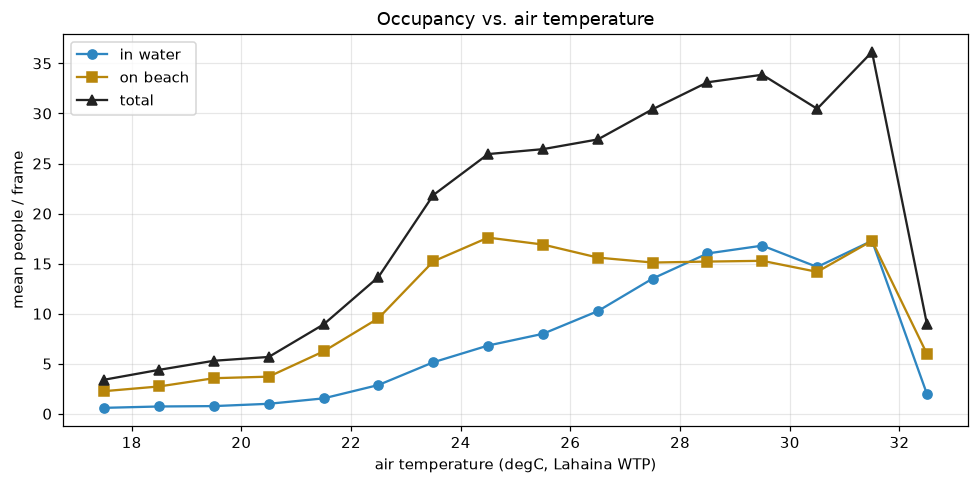

,people_beach,people_water,people_total
tbin,,,
"(17, 18]",2.3,0.6,3.4
"(18, 19]",2.7,0.7,4.4
"(19, 20]",3.6,0.8,5.3
"(20, 21]",3.7,1.0,5.7
"(21, 22]",6.2,1.5,8.9
"(22, 23]",9.5,2.9,13.7
"(23, 24]",15.2,5.1,21.8
"(24, 25]",17.6,6.8,25.9
"(25, 26]",16.9,8.0,26.4


In [8]:
jj = j[j.ts_suspect == 0].dropna(subset=['Tair_avg']).copy()
jj['tbin'] = pd.cut(jj['Tair_avg'], np.arange(17, 34, 1))
gb = jj.groupby('tbin', observed=True)[['people_beach','people_water',
                                      'people_total']].mean()
mids = [iv.mid for iv in gb.index]
fig, ax = plt.subplots(figsize=(9,4.5))
ax.plot(mids, gb['people_water'], '-o', color='#2e86c1', label='in water')
ax.plot(mids, gb['people_beach'], '-s', color='#b8860b', label='on beach')
ax.plot(mids, gb['people_total'], '-^', color='#222222', label='total')
ax.set_xlabel('air temperature (degC, Lahaina WTP)')
ax.set_ylabel('mean people / frame')
ax.set_title('Occupancy vs. air temperature'); ax.legend()
plt.tight_layout(); plt.savefig(OUT/'temp_response.png'); plt.show()
gb.round(1)

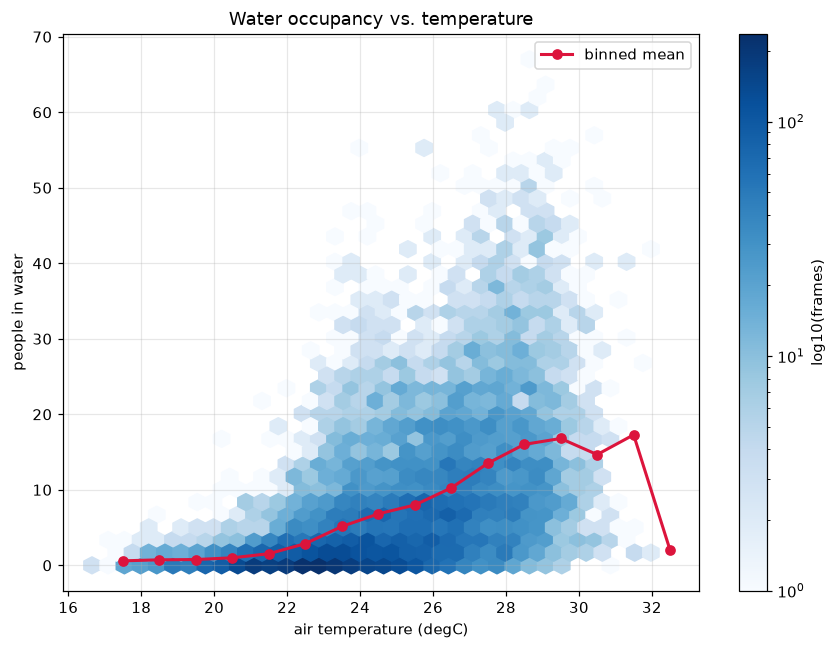

In [9]:
fig, ax = plt.subplots(figsize=(8,6))
hb = ax.hexbin(jj['Tair_avg'], jj['people_water'], gridsize=35,
               cmap='Blues', mincnt=1, bins='log')
ax.plot(mids, gb['people_water'], '-o', color='crimson', lw=2, label='binned mean')
ax.set_xlabel('air temperature (degC)'); ax.set_ylabel('people in water')
ax.set_title('Water occupancy vs. temperature'); ax.legend()
fig.colorbar(hb, ax=ax, label='log10(frames)')
plt.tight_layout(); plt.savefig(OUT/'temp_water_scatter.png'); plt.show()

In [ ]:
# humidity, wind, rainfall, albedo (daylight proxy)
fig, axs = plt.subplots(2, 2, figsize=(12,8))
specs = [('RH_avg','relative humidity (%)', np.arange(50,101,5)),
         ('WS_1_Avg','wind speed (m/s)', np.arange(0,14,1)),
         ('RF_1_Tot300s','5-min rain (mm)', None),
         ('Albedo_1_Avg','albedo (daylight proxy)', np.arange(0,.45,.05))]
for ax, (c, lab, bins) in zip(axs.flat, specs):
    sub = jj.dropna(subset=[c]).copy()
    if c == 'RF_1_Tot300s':
        sub['rain'] = np.where(sub[c] > 0.05, 'rainy (>0.05mm/5min)', 'dry')
        g2 = sub.groupby('rain')[['people_beach','people_water',
              'people_total']].mean()
        bars = g2.plot(kind='bar', ax=ax, color=['#b8860b','#2e86c1','#444444'])
        for cont in ax.containers:
            ax.bar_label(cont, fmt='%.1f', fontsize=8)
        ax.set_title('Occupancy on dry vs rainy days'); ax.tick_params(rotation=0)
        nr = (sub[c] > 0.05).sum(); nd = (sub[c] <= 0.05).sum()
        ax.set_xlabel(f'n = {nd:,} dry / {nr:,} rainy frames')
        d_tot, r_tot = g2.people_total.iloc[0], g2.people_total.iloc[1]
        print(f'rain frames (>0.05mm/5min): {nr}  | mean occupancy '
              f'dry {d_tot:.1f} vs rainy {r_tot:.1f} '
              f'({100*(r_tot/d_tot-1):+.0f}%)')
        rr = sub[sub[c] > 0.05]
        print(f'  within rainy frames: r(rain_intensity,total) = '
              f'{rr[[c,"people_total"]].corr().iloc[0,1]:+.3f},  '
              f'r(Tair,total) = {rr[["Tair_avg","people_total"]].corr().iloc[0,1]:+.3f}')
        continue
    sub['b'] = pd.cut(sub[c], bins)
    g2 = sub.groupby('b', observed=True)[['people_beach','people_water']].mean()
    xs = [iv.mid for iv in g2.index]
    ax.plot(xs, g2['people_water'], '-o', color='#2e86c1', label='water')
    ax.plot(xs, g2['people_beach'], '-s', color='#b8860b', label='beach')
    ax.set_xlabel(lab); ax.set_ylabel('people/frame'); ax.legend()
    ax.set_title(f'Occupancy vs {lab}')
plt.tight_layout(); plt.savefig(OUT/'weather_other.png'); plt.show()

## 5. Tide and waterline


pre-move  n=  973  r(tide, pct_water)=-0.163  r(tide, wl_y)=-0.156
post-move n= 8967  r(tide, pct_water)=-0.113  r(tide, wl_y)=-0.121


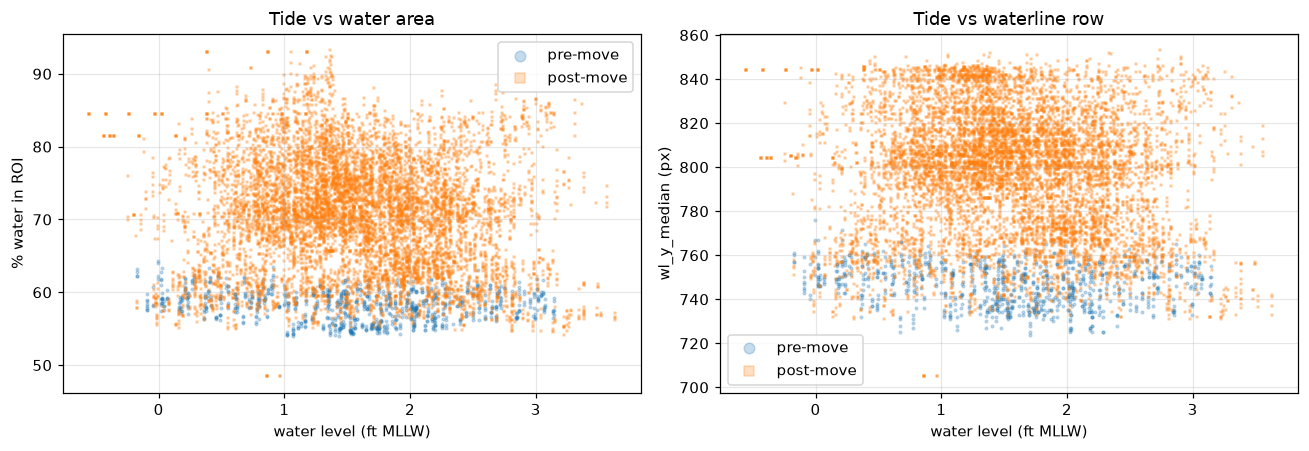

In [11]:
tide = pd.read_csv(TIDE_CSV)
tide.columns = [c.strip() for c in tide.columns]
tide['utc'] = pd.to_datetime(tide['Date Time'], format='%m/%d/%Y %H:%M')
tide = tide.rename(columns={'Water Level':'wl_ft'}).sort_values('utc')

wl = pd.read_csv(WATERLINE_CSV)
d2 = day.merge(wl[['image','wl_y_median']], on='image', how='left')
jt = pd.merge_asof(d2.sort_values('utc'), tide[['utc','wl_ft']],
                   on='utc', direction='nearest', tolerance=pd.Timedelta('45min'))
jt = jt.dropna(subset=['wl_ft'])

for era, sub in [('pre-move',  jt[jt.utc  <  CAMERA_MOVE]),
                 ('post-move', jt[jt.utc  >= CAMERA_MOVE])]:
    r1 = sub[['wl_ft','pct_water']].corr().iloc[0,1]
    r2 = sub[['wl_ft','wl_y_median']].corr().iloc[0,1]
    print(f'{era:9s} n={len(sub):5d}  r(tide, pct_water)={r1:+.3f}  '
          f'r(tide, wl_y)={r2:+.3f}')

fig, axs = plt.subplots(1, 2, figsize=(12,4.2))
for era, mk, sub in [('pre-move','o', jt[jt.utc < CAMERA_MOVE]),
                     ('post-move','s', jt[jt.utc >= CAMERA_MOVE])]:
    axs[0].scatter(sub['wl_ft'], sub['pct_water'], s=3, alpha=.25, label=era, marker=mk)
    axs[1].scatter(sub['wl_ft'], sub['wl_y_median'], s=3, alpha=.25, label=era, marker=mk)
axs[0].set_xlabel('water level (ft MLLW)'); axs[0].set_ylabel('% water in ROI')
axs[0].legend(markerscale=4); axs[0].set_title('Tide vs water area')
axs[1].set_xlabel('water level (ft MLLW)'); axs[1].set_ylabel('wl_y_median (px)')
axs[1].legend(markerscale=4); axs[1].set_title('Tide vs waterline row')
plt.tight_layout(); plt.savefig(OUT/'tide_response.png'); plt.show()

## 6. Detection-confidence audit + daily export


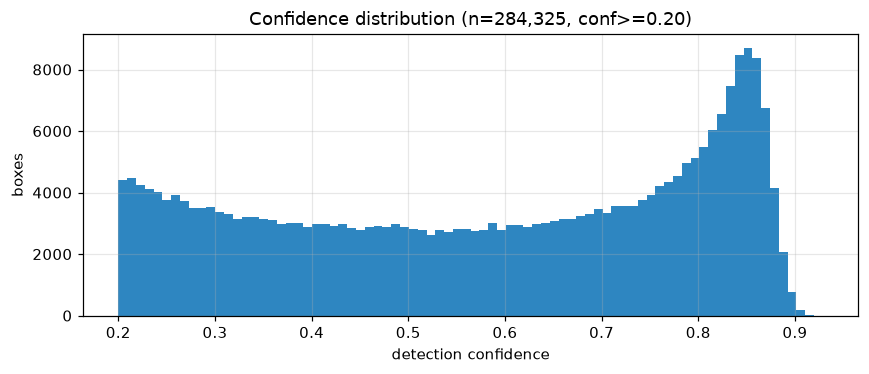

count    284325.000
mean          0.581
std           0.218
min           0.200
25%           0.380
50%           0.607
75%           0.790
max           0.929
Name: conf, dtype: float64


In [12]:
det = pd.read_csv(DETECTIONS_CSV, usecols=['conf'])
fig, ax = plt.subplots(figsize=(8,3.5))
ax.hist(det['conf'], bins=80, color='#2e86c1')
ax.set_xlabel('detection confidence'); ax.set_ylabel('boxes')
ax.set_title(f'Confidence distribution (n={len(det):,}, conf>=0.20)')
plt.tight_layout(); plt.savefig(OUT/'det_conf_hist.png'); plt.show()
print(det['conf'].describe().round(3))

In [13]:
daily_out = (day.set_index('local')
    .resample('1D')
    .agg(frames=('image','size'),
         ts_suspect=('ts_suspect','sum'),
         people_beach_mean=('people_beach','mean'),
         people_water_mean=('people_water','mean'),
         people_other_mean=('people_other','mean'),
         people_total_mean=('people_total','mean'),
         people_total_max=('people_total','max'),
         pct_beach_mean=('pct_beach','mean'),
         pct_water_mean=('pct_water','mean'),
         beach_px_mean=('px_beach','mean')))
daily_out = daily_out[daily_out.frames >= MIN_F]
daily_out['beach_m2_mean'] = daily_out['beach_px_mean'] * M2_PER_PX
daily_out['m2_per_beach_person'] = (daily_out['beach_m2_mean']
                                  / daily_out['people_beach_mean'].replace(0, np.nan))
out_csv = OUT / 'daily_beach_metrics.csv'
daily_out.round(3).to_csv(out_csv)
print(f'wrote {out_csv} ({len(daily_out)} days)')
daily_out.round(1).tail(10)

wrote out\daily_beach_metrics.csv (245 days)


,frames,ts_suspect,people_beach_mean,people_water_mean,people_other_mean,people_total_mean,people_total_max,pct_beach_mean,pct_water_mean,beach_px_mean,beach_m2_mean,m2_per_beach_person
local,,,,,,,,,,,,
2026-10-09,50,0,16.4,10.1,0.8,27.3,56.0,38.2,61.5,239574.6,3306.1,201.6
2026-10-10,51,0,16.8,11.7,0.9,29.4,65.0,38.8,60.8,243849.2,3365.1,200.5
2026-10-11,48,0,13.1,9.8,0.9,23.8,52.0,40.1,59.6,251382.7,3469.1,265.6
2026-10-12,51,0,12.5,9.2,0.6,22.3,51.0,41.4,58.2,259979.2,3587.7,287.2
2026-10-13,51,0,11.8,7.6,0.5,19.9,42.0,42.4,57.2,266217.3,3673.8,310.7
2026-10-14,50,0,13.6,7.5,0.6,21.7,54.0,43.9,55.7,275310.9,3799.3,279.4
2026-10-16,41,0,13.4,7.1,0.8,21.2,56.0,42.0,57.6,263566.2,3637.2,272.1
2026-10-17,50,0,12.5,8.2,1.1,21.9,50.0,43.1,56.5,270667.9,3735.2,297.9
2026-10-18,48,0,14.1,7.2,0.7,22.1,50.0,42.8,56.8,268626.6,3707.0,262.8


## 7. Detection annotation scale + occupancy distribution

`data/annotation_sizes.csv` lists every person box in the tiled training set
(equivalent square side = sqrt(w*h) at 640 px tiles). The heavy small-object
mass â€” median ~13 px, ~47% of boxes under 12 px â€” is the empirical
justification for the P2 (stride-4) detection head.

In [ ]:
ann = pd.read_csv(DATA / 'annotation_sizes.csv')
fig, axs = plt.subplots(1, 2, figsize=(13,4))
bins = np.arange(0, 100, 2)
axs[0].hist(ann['size_px'], bins=bins, color='#2e86c1', edgecolor='white', lw=.3)
axs[0].axvline(ann.size_px.median(), color='k', ls='--',
               label=f"median {ann.size_px.median():.1f} px")
axs[0].set_xlabel('box equivalent side (px @640)'); axs[0].set_ylabel('boxes')
axs[0].set_title(f'Person annotation sizes (n={len(ann):,})'); axs[0].legend()
for s, c in [('train','#2e86c1'), ('valid','#b8860b'), ('test','#c0392b')]:
    sub = ann[ann.split==s]['size_px']
    axs[1].hist(sub, bins=bins, density=True, histtype='step',
                lw=1.5, label=f'{s} (n={len(sub):,})', color=c)
axs[1].set_xlabel('box equivalent side (px @640)'); axs[1].set_ylabel('density')
axs[1].set_title('By split'); axs[1].legend()
plt.tight_layout(); plt.savefig(OUT/'annotation_sizes.png'); plt.show()
print(f"median {ann.size_px.median():.1f} px | <12px: {100*(ann.size_px<12).mean():.1f}% | <20px: {100*(ann.size_px<20).mean():.1f}%")

In [ ]:
# per-frame occupancy distribution
fig, ax = plt.subplots(figsize=(9,4))
ax.hist(day['people_total'], bins=np.arange(0, 120, 2), color='#444444')
ax.axvline(day.people_total.median(), color='r', ls='--',
           label=f"median {int(day.people_total.median())}")
ax.set_xlabel('people per frame'); ax.set_ylabel('frames')
ax.set_title('Frame occupancy distribution'); ax.legend()
plt.tight_layout(); plt.savefig(OUT/'occupancy_distribution.png'); plt.show()

# beach-area trend (fraction of ROI that is sand), daily median
barea = day.set_index('local')['pct_beach'].resample('1D').median()
fig, ax = plt.subplots(figsize=(14,3.5))
ax.plot(barea.index, barea.values, color='#b8860b', lw=1.2)
ax.axvline(CAMERA_MOVE - pd.Timedelta(hours=10), color='k', ls='--', lw=1,
           label='camera move')
ax.set_ylabel('% beach in ROI'); ax.set_title('Visible sand fraction over time')
ax.legend()
plt.tight_layout(); plt.savefig(OUT/'beach_area_trend.png'); plt.show()